In [1]:
using Revise
using LinearAlgebra
using NLsolve
using Plots
using LaTeXStrings

gr();
# pyplot();
# plotlyjs();

In [2]:
BLAS.set_num_threads(1)

In [3]:
using GaussianSpectralDensities

┌ Info: Precompiling GaussianSpectralDensities [d24dbb70-b498-4c6e-be6a-7c28347cbb8b]
└ @ Base loading.jl:1278


# Dynamics of a random neural network with one planted memory

$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
$$

$$
\begin{aligned}
\frac{d x_i}{dt} &= -x_i + \sum_{j = 1}^N \tilde{J}_{ij} \tanh x_j \ , \\
\tilde{J} &= \frac{\hat{\bm{x}} \tanh \hat{\bm{x}}}{\|\tanh \hat{\bm{x}}\|^2} + \sigma J \, , \\
\langle J_{ij} J_{kl} \rangle &= \frac{1}{N} \left(\delta_{ik} \delta_{jl} + \tau \delta_{il} \delta_{kj} \right) \, .
\end{aligned}
$$

The memory $\hat{\bm{x}}$ is a randomly sampled vector, and the model
is set up such that, in the absence of coupling noise ($\sigma = 0$),
there is a fixed point at $\bm{x} = \hat{\bm{x}}$. What happens as
noise is turned on, and what is the effect of symmetry $\tau$?

Note that the $\tanh$ breaks rotational symmetry, so different
$\hat{\bm{x}}$ with the same norm do not necessarily give equivalent
dynamics. Should this inform our choice of measure for sampling
memories? No, I think sampling something like a Gaussian $\hat{\bm{x}}$
is the most sensible approach. It maintains permutation invariance
but not full rotational invariance, which actually seems desirable in
a nonlinear model.

Let's run some simulations.

In [4]:
function network_f!(dx, x, J̃, t)
    mul!(dx, J̃, tanh.(x))
    dx .-= x
end

function network_jac!(jac, x, J̃, t)
    for j in 1:length(x)
        for i in 1:length(x)
            jac[i, j] = J̃[i, j] / (cosh(x[j])^2)
        end
        jac[j, j] -= one(eltype(jac))
    end
end

function poor_mans_network_jac!(jac, x, J̃, t, dx)
    xx = copy(x)
    fx = similar(xx)
    fxdx = similar(xx)
    network_f!(fx, xx, J̃, t)
    for j in 1:N
        xx[j] += dx
        network_f!(fxdx, xx, J̃, t) 
        jac[:, j] = (fxdx - fx) / (xx[j] - x[j])
        xx[j] = x[j]
    end
end

poor_mans_network_jac! (generic function with 1 method)

In [5]:
ftype = Float64

N = 256
s = one(ftype)
x̂ = s * randn(ftype, N)
tx̂ = tanh.(x̂)
Ĵ = x̂ * tx̂' / dot(tx̂, tx̂)
Ĵ[diagind(Ĵ)] .= zero(ftype);

In [6]:
σ = ftype(0.4)
τ = ftype(0.5)

J = randn(ftype, N, N) / ftype(sqrt(N))
J = partially_hermitize(J, τ)
J[diagind(J)] .= zero(ftype)

J̃ = Ĵ + σ * J;

In [7]:
# Verify Jacobian
jaca = similar(J̃)
jacb = similar(J̃)
network_jac!(jaca, x̂, J̃, zero(ftype))
poor_mans_network_jac!(jacb, x̂, J̃, zero(ftype), sqrt(eps(ftype)))
opnorm(jacb - jaca)

6.538764090522425e-7

In [8]:
sol = nlsolve(
    (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
    (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
    x̂;
    method=:newton,
    ftol=sqrt(eps(ftype)),
)
if !converged(sol)
    error("failed to converge")
end
x₀ = sol.zero
jac = similar(J̃)
network_jac!(jac, x₀, J̃, zero(ftype))
jacevs = eigvals(jac)
println(maximum(real(jacevs)))

-0.5308418693777635


In [9]:
R = Diagonal(cosh.(x₀).^(-2))
ensemble = MatrixEnsemble(Ĵ * R - I, σ * I, R, τ)

Mevs = unique(eigvals(ensemble.M))
A, _J = sample(ftype, ensemble)
Aevs = eigvals(A);

In [10]:
import LazySets

region = spectral_region(Aevs)
xs, ys, zs = autogrid(region);

In [11]:
i, j = 20, 105
za = zs[i, j + 1]
zb = zs[i - 1, j]
zc = zs[i, j];

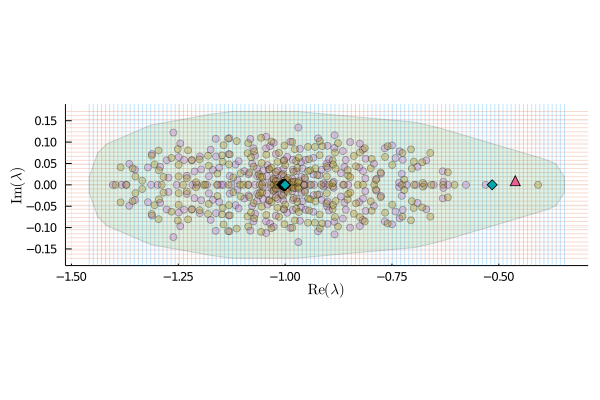

In [12]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

In [13]:
objective = Fixk();
algorithm = Rampδ²();

In [14]:
verbosity = 3;

solver = SpectralSolver(ensemble, objective, algorithm);
solutiona = solve!(solver, za; verbosity=verbosity, store_trace=true);
solutionb = solve!(solver, zb; verbosity=verbosity, store_trace=true);
qa, δa² = solutiona.q, solutiona.δ²;
qb, δb² = solutionb.q, solutionb.δ²;
qc0, δc0² = GaussianSpectralDensities.select(qa, qb, δa², δb²);
GaussianSpectralDensities.print_q(qc0);
GaussianSpectralDensities.print_δ²(δc0²);
solutionc = solve!(
    solver, zc,
    qc0, δc0²;
    verbosity=verbosity, store_trace=true,
);
solver = nothing;  # Hand workspace over to GC

 z = -0.452 + i 0.010
---------------------------------------------------------------------------------------------
    μ       γ²         δ²                  q                k                   r
-------  ----------  ---------  ------------------------  ---------  ------------------------
  1.000   2.559e+02  2.560e+02   8.379e-03 + i-1.465e-04  3.519e-03   4.642e+01 + i-8.096e-01
  1.000   1.279e+02  1.280e+02   1.458e-02 + i-2.557e-04  6.716e-03   6.577e+01 + i-1.149e+00
  1.000   6.392e+01  6.400e+01   2.483e-02 + i-4.383e-04  1.258e-02   9.164e+01 + i-1.607e+00
  1.000   3.193e+01  3.200e+01   4.117e-02 + i-7.347e-04  2.293e-02   1.256e+02 + i-2.219e+00
  1.000   1.594e+01  1.600e+01   6.584e-02 + i-1.197e-03  4.024e-02   1.691e+02 + i-3.027e+00
  1.000   7.948e+00  8.000e+00   1.004e-01 + i-1.877e-03  6.709e-02   2.222e+02 + i-4.063e+00
  1.000   3.961e+00  4.000e+00   1.441e-01 + i-2.806e-03  1.048e-01   2.823e+02 + i-5.334e+00
  1.000   1.973e+00  2.000e+00   1.930e-01 + i-3.9

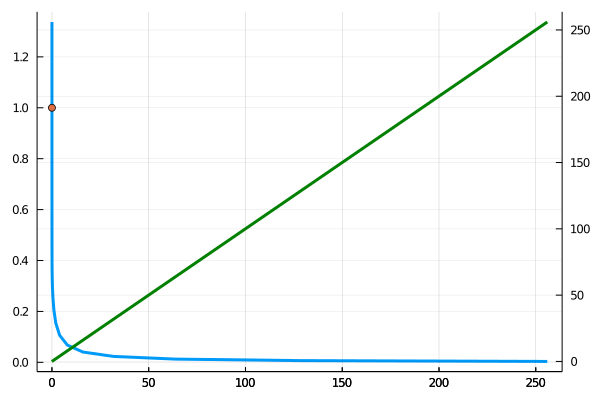

In [15]:
sol = solutionb

plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [16]:
chunks_per_thread = 1
problem = SpectralProblem(ensemble, objective, zs);
solution = solve(problem, algorithm; chunks_per_thread=1);

In [17]:
ρ, ρxs, ρys = spectral_density(solution, xs, ys);

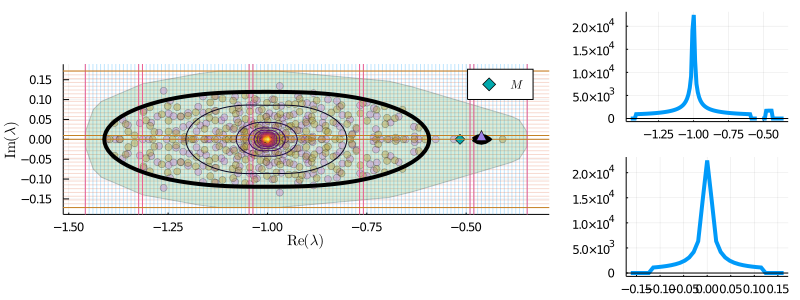

In [18]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(
    p,
    region,
    alpha=0.2,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label=L"M")

chunk_rows, chunk_cols = GaussianSpectralDensities.chunk_indices(
    size(zs), chunks_per_thread * Threads.nthreads()
)
chunk_xs, chunk_ys = xs[vcat(chunk_cols...)], ys[vcat(chunk_rows...)]
vline!(p, chunk_xs, label="")
hline!(p, chunk_ys, label="")

contour!(p, ρxs, ρys, ρ, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, linewidth=4)

vline!(p, [0.0], color=:black, label="")

ii, jj = 20, 105
scatter!(p, xs[[jj]], ys[[ii]], markershape=:utriangle, markersize=5, label="")

function plot_section(x, y, level)
    p = plot(x, y, linewidth=4, label="")
    return hline!(p, [level], color=:black, label="")
end

function plot_sections(xs, ys, f; x0=0.0, y0=0.0, level=0.0)
    i, j = argmin(abs2.(ρys .- y0)), argmin(abs2.(ρxs .- x0))
    return [plot_section(x, y, level) for (x, y) in ((xs, f[i, :]), (ys, f[:, j]))]
end

l = @layout [a{0.75w} [b; c]]
plot(p, plot_sections(ρxs, ρys, ρ, x0=-1)..., layout=l, size=(800, 300))

In [19]:
function fpoint(J̃, x₀)
    ftype = eltype(x₀)
    sol = nlsolve(
        (dx, x) -> network_f!(dx, x, J̃, zero(ftype)),
        (jac, x) -> network_jac!(jac, x, J̃, zero(ftype)),
        x₀;
        method=:newton,
        ftol=sqrt(eps(ftype)),
    )
    if !converged(sol)
        error("failed to converge")
    end
    return sol.zero
end

fpoint (generic function with 1 method)

In [20]:
x₀ = x̂
jac_ = similar(J̃)
σs = ftype(0.0):ftype(0.01):ftype(1.5)
evmaxs = fill(ftype(NaN), length(σs))
x₀s = fill(ftype(NaN), (length(x₀), length(σs)))
for (i, σ) in enumerate(σs)
    J̃ = Ĵ + σ * J
    try
        x₀s[:, i] = x₀ = fpoint(J̃, x₀)
    catch
        break
    end
    network_jac!(jac_, x₀, J̃, zero(ftype))
    evmaxs[i] = maximum(real(eigvals(jac_)))
end

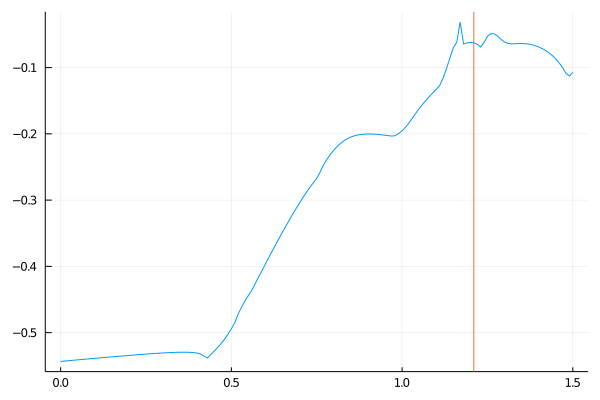

In [21]:
vl = [1.21]
plot(σs, evmaxs, label="")
vline!(vl, label="")

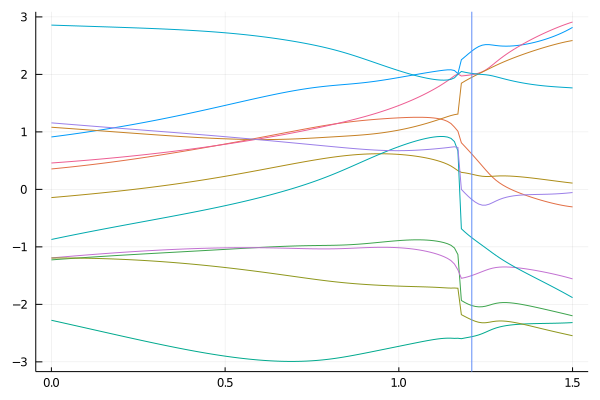

In [22]:
plot(σs, x₀s[1:12, :]', label="")
vline!(vl, label="")

In [23]:
println(repr("text/plain", [σs evmaxs]))

151×2 Array{Float64,2}:
 0.0   -0.543419
 0.01  -0.54294
 0.02  -0.542463
 0.03  -0.541989
 0.04  -0.541517
 0.05  -0.541049
 0.06  -0.540583
 0.07  -0.54012
 0.08  -0.53966
 0.09  -0.539203
 0.1   -0.538748
 0.11  -0.538297
 0.12  -0.537848
 0.13  -0.537401
 0.14  -0.536958
 0.15  -0.536518
 0.16  -0.536081
 0.17  -0.535647
 0.18  -0.535217
 0.19  -0.534792
 0.2   -0.534371
 0.21  -0.533955
 0.22  -0.533544
 0.23  -0.533141
 0.24  -0.532745
 0.25  -0.532358
 0.26  -0.531981
 0.27  -0.531616
 0.28  -0.531266
 0.29  -0.530933
 0.3   -0.53062
 0.31  -0.530331
 0.32  -0.530072
 0.33  -0.529849
 0.34  -0.529672
 0.35  -0.529551
 0.36  -0.529504
 0.37  -0.529555
 0.38  -0.529741
 0.39  -0.530127
 0.4   -0.530842
 0.41  -0.532206
 0.42  -0.535676
 0.43  -0.538104
 0.44  -0.532887
 0.45  -0.527609
 0.46  -0.522164
 0.47  -0.51635
 0.48  -0.509871
 0.49  -0.502456
 0.5   -0.494093
 0.51  -0.485023
 0.52  -0.47169
 0.53  -0.461315
 0.54  -0.451924
 0.55  -0.443773
 0.56  -0.435879
 0.57  -0.425